# Capstone Three: Predictive Maintenance — Preprocessing and Modeling

**Dataset:** NASA C-MAPSS FD001 turbofan degradation data. **Target:** remaining useful life (RUL), measured in cycles.  
**Business question:** Can engine sensor histories help maintenance teams estimate how many operating cycles remain before failure?

**Important:** NASA C-MAPSS is simulated turbofan data, not real factory maintenance records. Model results are illustrative of a predictive-maintenance workflow, not validated maintenance recommendations.

### Data setup
Download the **CMAPSSData.zip** archive from [NASA Prognostics Center of Excellence](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/). Extract `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt` into `data/` beside the `notebooks/` directory. No raw data is redistributed here. Run all cells in order from the repository root or from inside `notebooks/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists(): ROOT = ROOT.parent
DATA = ROOT / 'data'; OUT = ROOT / 'outputs'; OUT.mkdir(exist_ok=True)
cols = ['engine_id','cycle','setting_1','setting_2','setting_3'] + [f'sensor_{i}' for i in range(1,22)]
def load_table(name):
    p = DATA / name
    if not p.exists(): raise FileNotFoundError(f'Missing {p}. Download and extract NASA C-MAPSS FD001 data; see README.md.')
    df = pd.read_csv(p, sep=r'\s+', header=None)
    df = df.dropna(axis=1, how='all')
    if df.shape[1] != len(cols): raise ValueError(f'{name}: expected {len(cols)} columns, got {df.shape[1]}')
    df.columns = cols
    return df
train_raw = load_table('train_FD001.txt')
test_raw = load_table('test_FD001.txt')
rul_path = DATA / 'RUL_FD001.txt'
if not rul_path.exists(): raise FileNotFoundError(rul_path)
test_rul = pd.read_csv(rul_path, sep=r'\s+', header=None).iloc[:,0].astype(float)
print('Training rows:',len(train_raw),'engines:',train_raw.engine_id.nunique())
print('Test rows:',len(test_raw),'engines:',test_raw.engine_id.nunique())
display(train_raw.head())

Training rows: 20631 engines: 100
Test rows: 13096 engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 1. Audit the data and feature types

The NASA FD001 data contain numeric operating settings and sensor measurements, along with an engine ID and cycle index. There are **no categorical predictors requiring one-hot encoding** in this subset. `engine_id` identifies a unit and is used for grouped splitting, not as a predictor. `cycle` is numeric and is retained as a feature.

In [2]:
print('Missing values (train):', int(train_raw.isna().sum().sum()))
print('Duplicate engine-cycle keys:',int(train_raw.duplicated(['engine_id','cycle']).sum()))
print('Categorical columns:',train_raw.select_dtypes(include=['object','category']).columns.tolist())
assert not train_raw.duplicated(['engine_id','cycle']).any(), 'Duplicate engine-cycle records'
assert not train_raw.isna().any().any(), 'Unexpected missing values'
print(train_raw.describe().round(2).T.to_string())

Missing values (train): 0
Duplicate engine-cycle keys: 0
Categorical columns: []
             count     mean    std      min      25%      50%      75%      max
engine_id  20631.0    51.51  29.23     1.00    26.00    52.00    77.00   100.00
cycle      20631.0   108.81  68.88     1.00    52.00   104.00   156.00   362.00
setting_1  20631.0    -0.00   0.00    -0.01    -0.00     0.00     0.00     0.01
setting_2  20631.0     0.00   0.00    -0.00    -0.00     0.00     0.00     0.00
setting_3  20631.0   100.00   0.00   100.00   100.00   100.00   100.00   100.00
sensor_1   20631.0   518.67   0.00   518.67   518.67   518.67   518.67   518.67
sensor_2   20631.0   642.68   0.50   641.21   642.33   642.64   643.00   644.53
sensor_3   20631.0  1590.52   6.13  1571.04  1586.26  1590.10  1594.38  1616.91
sensor_4   20631.0  1408.93   9.00  1382.25  1402.36  1408.04  1414.55  1441.49
sensor_5   20631.0    14.62   0.00    14.62    14.62    14.62    14.62    14.62
sensor_6   20631.0    21.61   0.00    2

## 2. Define the target and avoid leakage

For training engines, the final recorded cycle is the simulated failure cycle. Thus `RUL = final_cycle − current_cycle`. The provided NASA test RUL file gives the **true RUL at the last observed cycle** for each held-out test engine. We evaluate on one final observation per test engine, consistent with those labels.

**Important:** We never calculate test RUL using the maximum observed test cycle, since those test trajectories are truncated before failure.

In [3]:
max_cycles = train_raw.groupby('engine_id')['cycle'].transform('max')
train = train_raw.copy()
train['RUL'] = max_cycles - train['cycle']
assert train.RUL.min() == 0
assert len(test_rul) == test_raw.engine_id.nunique(), 'NASA test labels and engines do not align'
# FD001 test file engine IDs correspond in ascending order to RUL_FD001 entries.
test_last = test_raw.sort_values(['engine_id','cycle']).groupby('engine_id',as_index=False).tail(1).copy()
test_last = test_last.sort_values('engine_id').reset_index(drop=True)
assert test_last.engine_id.tolist() == list(range(1,len(test_rul)+1)), 'Unexpected test engine ordering'
test_last['RUL'] = test_rul.to_numpy()
print('Training target summary:');display(train.RUL.describe())
print('Test targets:',len(test_last))

Training target summary:


count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

Test targets: 100


## 3. Train/validation split by engine

This dataset has multiple sequential rows per engine. A random row-level split would leak highly related sensor histories across train and validation sets. Instead, split **whole engines** into development training and validation groups. The NASA-provided test set is kept completely separate for final evaluation.

In [4]:
splitter = GroupShuffleSplit(n_splits=1,test_size=0.20,random_state=42)
idx_train,idx_val = next(splitter.split(train, groups=train['engine_id']))
dev_train = train.iloc[idx_train].copy()
dev_val = train.iloc[idx_val].copy()
assert set(dev_train.engine_id).isdisjoint(set(dev_val.engine_id))
print('Development train:',dev_train.shape,'engines:',dev_train.engine_id.nunique())
print('Validation:',dev_val.shape,'engines:',dev_val.engine_id.nunique())
print('NASA held-out test engines:',test_last.engine_id.nunique())

Development train: (16561, 27) engines: 80
Validation: (4070, 27) engines: 20
NASA held-out test engines: 100


## 4. Identify features, scale numeric data, and save clean datasets

Constant columns offer no predictive variation. They are removed based **only on development training data**. All remaining predictors are numeric, so one-hot encoding is not needed. A `SimpleImputer` and `StandardScaler` will be fitted **inside each model pipeline on training data only**, preventing leakage from validation/test data. Tree models do not require scaling, but scaled features make the model comparison workflow consistent.

In [5]:
candidate_features = ['cycle','setting_1','setting_2','setting_3'] + [f'sensor_{i}' for i in range(1,22)]
constant_cols = [c for c in candidate_features if dev_train[c].nunique(dropna=True)<=1]
features = [c for c in candidate_features if c not in constant_cols]
print('Constant columns dropped:',constant_cols)
print('Predictors:',features)
# Audit scaler on train only (model pipelines fit their own scaler later).
scaler_audit = StandardScaler().fit(dev_train[features])
scaled_train = scaler_audit.transform(dev_train[features])
print('Scaled development training mean (first 5):',np.round(scaled_train.mean(axis=0)[:5],3))
print('Scaled development training std (first 5):',np.round(scaled_train.std(axis=0)[:5],3))
for name,frame in [('development_train',dev_train),('validation',dev_val),('nasa_test_last_cycle',test_last)]:
    frame.to_csv(OUT/f'{name}.csv',index=False)
(OUT/'feature_columns.json').write_text(__import__('json').dumps({'features':features,'constant_columns':constant_cols},indent=2))
print('Saved cleaned split CSVs and feature metadata to outputs/')

Constant columns dropped: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Predictors: ['cycle', 'setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Scaled development training mean (first 5): [-0.  0. -0. -0.  0.]
Scaled development training std (first 5): [1. 1. 1. 1. 1.]
Saved cleaned split CSVs and feature metadata to outputs/


## 5. Visual quality checks

Sensor measurements have different scales, supporting numeric standardization. Inspect degradation trends and RUL distribution before modeling.

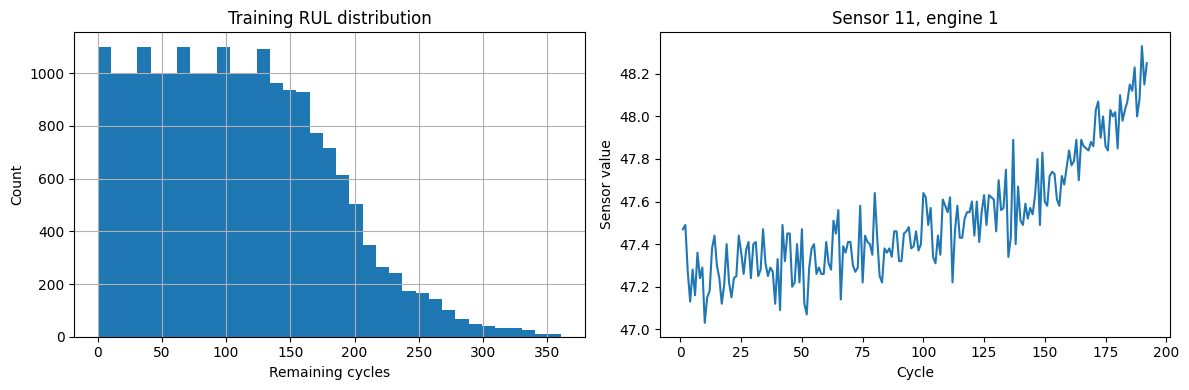

In [6]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
train.RUL.hist(ax=ax[0],bins=35);ax[0].set(title='Training RUL distribution',xlabel='Remaining cycles',ylabel='Count')
example_id = train.engine_id.iloc[0]
example = train[train.engine_id==example_id]
ax[1].plot(example.cycle,example.sensor_11);ax[1].set(title=f'Sensor 11, engine {example_id}',xlabel='Cycle',ylabel='Sensor value')
plt.tight_layout();plt.savefig(OUT/'eda_overview.png',dpi=150);plt.show()

## Preprocessing conclusions

- **Categorical encoding:** Not applicable to FD001; the predictors are numeric.
- **Scaling:** Appropriate because sensor magnitudes differ; fitted only to training observations.
- **Splitting:** Engine-grouped development/validation split; NASA's original test engines remain held out.
- **Target:** Continuous RUL in operating cycles, making this a **regression** problem.
- **Artifacts:** Cleaned split CSVs and feature metadata are written to `outputs/`.

Proceed to `02_modeling.ipynb`.